# 03 · Estantes sintéticos (Fase 2)

**Objetivo:** fabricar miles de imágenes de *nuestro* estante (3 niveles, una sola fila: latas arriba,
botellas chicas al medio, botellas grandes abajo) con etiquetas y conteos **exactos**, para entrenar el
detector de 1 clase (`producto`) y el YOLO multiclase (9 clases).

## ¿Qué son los datos sintéticos?

Imágenes **generadas por programa** en lugar de fotografiadas. Acá usamos *copy-paste*: recortamos envases
reales de fotos de entrenamiento, les quitamos el fondo y los "pegamos" sobre un estante dibujado. Como el
programa decide dónde va cada envase, **sabe exactamente** qué hay en la imagen.

## ¿Por qué ayudan?

1. **Conteos y cajas exactos gratis**: no hay que etiquetar a mano ni hay errores de etiquetado.
2. **Control de la distribución**: podemos balancear las 9 clases (en los datasets públicos hay 1000
   Coca botellas y 31 Fanta latas), decidir cuántos envases por nivel, el orden, la luz, el fondo.
3. **Casos con cero**: niveles vacíos, estantes medio vacíos e imágenes sin ningún envase. El modelo tiene
   que aprender a contar 0, y en los datasets públicos casi no hay ejemplos así.
4. **Nuestra geometría**: una fila, 3 niveles, tira portaprecios: algo que no aparece en los datasets.

## Riesgos: la brecha de dominio

Un sintético nunca es igual a una foto real: bordes pegados, luz y sombras que no coinciden, envases
fotografiados desde otro ángulo, recortes de poca resolución agrandados. Un modelo puede aprender esos
artefactos ("si tiene borde raro, es un producto") y fallar en fotos reales. Por eso:

* los sintéticos **solo se suman al entrenamiento**; **validación y prueba son SIEMPRE fotos reales**;
* los objetos se toman **solo del split train** (si no, filtraríamos imágenes de evaluación);
* se compara entrenar *con* y *sin* sintéticos midiendo en fotos reales.


In [1]:
import os, sys, csv, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
# los datos pesados viven en la carpeta principal (INVENTARIO_DATOS); si no está definida, se usa <repo>/datos
from src.config import DIR_DATOS, cargar_clases, nombres_clases
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("config", "InlineBackend.figure_format = 'jpeg'")
plt.rcParams["figure.dpi"] = 60
from PIL import Image
NOMBRES = nombres_clases()
DIR_SINT = DIR_DATOS / "sinteticos"
print(DIR_SINT, [p.name for p in DIR_SINT.iterdir()] if DIR_SINT.exists() else "(no existe)")

C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\datos\sinteticos ['.gitkeep', 'lote_3000', 'lote_500', '_objetos']


## Paso 1 · Biblioteca de envases sin fondo

`scripts/sinteticos_objetos.py` recorre las cajas del **train** de la fusión y se queda solo con envases
**completos, parados y poco tapados**; les quita el fondo con `rembg` (red U²-Net), limpia la máscara (une la
tapa con el cuerpo, endereza) y descarta los de **color incoherente con la clase** (encontramos etiquetas
equivocadas en el dataset de origen: latas de otra marca como `coca_lata`, botellas vacías como `coca_botella`).


{'7up_lata': 69, 'coca_botella': 80, 'coca_lata': 114, 'fanta_botella': 94, 'fanta_lata': 8, 'pepsi_botella': 72, 'pepsi_lata': 52, 'sprite_botella': 117, 'sprite_lata': 52}


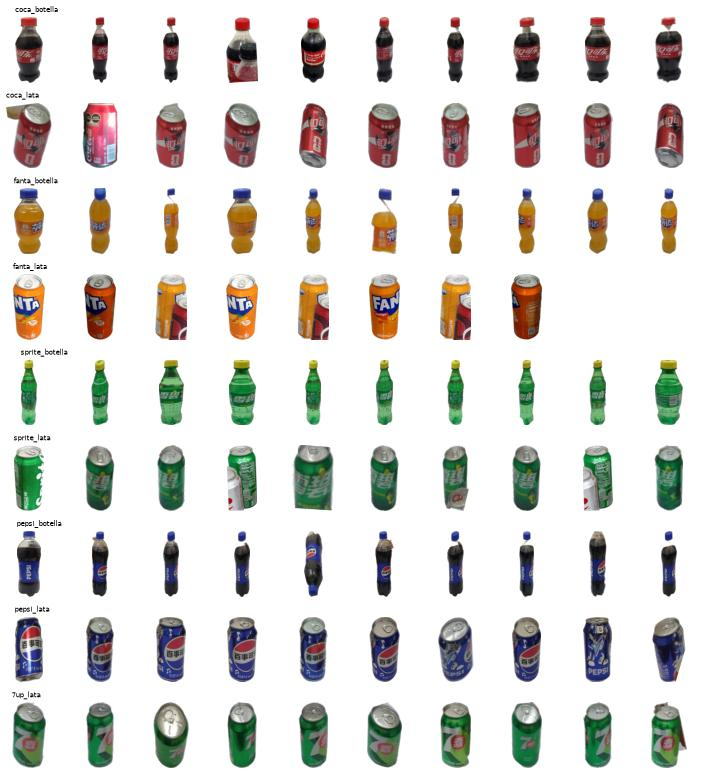

In [2]:
from src.sinteticos import objetos as obj
bib = obj.cargar_biblioteca(DIR_SINT / "_objetos")
print({k: len(v) for k, v in sorted(bib.items())})
fig, ax = plt.subplots(len(NOMBRES), 10, figsize=(12, 13))
rng = np.random.default_rng(0)
for i, c in enumerate(NOMBRES):
    rutas = bib.get(c, [])
    for j in range(10):
        a = ax[i, j]; a.axis("off")
        if j < len(rutas):
            im = Image.open(rutas[rng.integers(len(rutas))])
            a.imshow(im);
        if j == 0: a.set_title(c, fontsize=8, loc="left")
plt.tight_layout()

In [3]:
rech = list(csv.DictReader(open(DIR_SINT / "_objetos" / "rechazos.csv", encoding="utf-8")))
from collections import Counter
print("motivos de rechazo de la máscara/color:", Counter(r["motivo"].split("_0")[0] for r in rech))

motivos de rechazo de la máscara/color: Counter({'mascara_baja': 110, 'cobertura': 93, 'color_no_rojo': 21, 'color_rojo': 21, 'aspecto_final': 14, 'color_naranja': 10, 'mascara_angosta': 9, 'color_verde': 9, 'color_oscuro': 4, 'cobertura_1.00': 1})


## Paso 2 · Componer un estante

`src/sinteticos/composicion.py` trabaja en **centímetros** (como la maqueta de `maqueta/GUIA.md`) y los pasa a
píxeles: ancho 60–80 cm, niveles ≈ 35/25/15 cm, tablas, tira portaprecios con precios "Bs N" que tapa la base de
los envases. Cada envase se escala a su **tamaño real** (botella grande ≈ 31 cm, chica ≈ 22 cm, lata ≈ 12 cm),
se apoya en el piso del nivel y se varía: rotación ±5°, color, solapamiento leve, borde suavizado, sombra.
Después se aplica perspectiva leve, luz (fría, natural, cálida, poca luz, flash), desenfoque y ruido.

Las **cajas** salen de un "mapa de ids" que se dibuja igual que la imagen: la caja es la parte **visible**
del envase. Regla: si un envase queda visible menos del 40 % (tapado más del 60 %), no se cuenta (se lo saca
de la escena para que no quede pegado sin etiqueta).


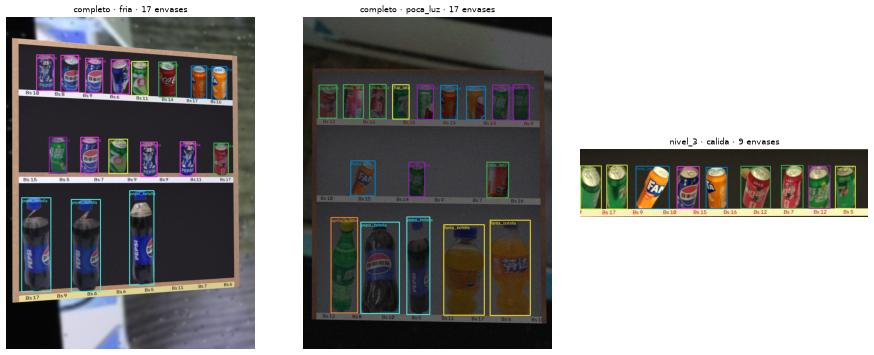

In [4]:
from src.sinteticos import fondos as fnd
from src.sinteticos.composicion import Parametros, componer, dibujar_cajas
fondos_reales = fnd.listar_fondos_reales(DIR_DATOS / "fusion" / "multiclase" / "images" / "train", None)
clases = cargar_clases()["clases"]
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
for k, sem in enumerate([3, 11, 25]):
    esc = componer(np.random.default_rng([123, sem]), bib, clases, fondos_reales, Parametros())
    ax[k].imshow(dibujar_cajas(esc.imagen, esc.cajas, NOMBRES)); ax[k].axis("off")
    conteo = Counter(NOMBRES[c[0]] for c in esc.cajas)
    ax[k].set_title(f"{esc.meta['modo']} · {esc.meta['luz']} · {sum(conteo.values())} envases", fontsize=9)
plt.tight_layout()

## Paso 3 · Un lote completo

```
python scripts/sinteticos_generar.py --n 3000 --semilla 1 --salida lote_3000 --procesos 4
```

Deja dos árboles YOLO (`multiclase/` y `1clase/`, con las imágenes enlazadas, no copiadas), `conteos.csv`
(verdad exacta por imagen), `meta.csv` y `resumen.json`. Para entrenar con Ultralytics se usa
`data_mixto.yaml`: train = real + sintético, **val/test = solo real**.


In [5]:
lote = DIR_SINT / "lote_500"
res = json.load(open(lote / "resumen.json", encoding="utf-8"))
print({k: res[k] for k in ("n", "semilla", "segundos", "imagenes_por_segundo", "imagenes_vacias")})
print(res["objetos_por_clase"])
print(open(lote / "multiclase" / "data_mixto.yaml", encoding="utf-8").read())

{'n': 500, 'semilla': 0, 'segundos': 41.6, 'imagenes_por_segundo': 12.03, 'imagenes_vacias': 34}
{'coca_botella': 614, 'coca_lata': 637, 'fanta_botella': 645, 'fanta_lata': 663, 'sprite_botella': 712, 'sprite_lata': 612, 'pepsi_botella': 631, 'pepsi_lata': 557, '7up_lata': 638}
# Entrenamiento mixto: train real + sintéticos; val/test SOLO reales.
path: C:/Users/limber/Documents/Semestres/2-2026/Preparacion Decisiones/IA/control_inventario/datos/fusion/multiclase
train:
  - C:/Users/limber/Documents/Semestres/2-2026/Preparacion Decisiones/IA/control_inventario/datos/fusion/multiclase/images/train
  - C:/Users/limber/Documents/Semestres/2-2026/Preparacion Decisiones/IA/control_inventario/datos/sinteticos/lote_500/multiclase/images
val: C:/Users/limber/Documents/Semestres/2-2026/Preparacion Decisiones/IA/control_inventario/datos/fusion/multiclase/images/val
test: C:/Users/limber/Documents/Semestres/2-2026/Preparacion Decisiones/IA/control_inventario/datos/fusion/multiclase/images/test
nc:

In [6]:
# verificación: conteos.csv coincide con las etiquetas
filas = list(csv.DictReader(open(lote / "conteos.csv", encoding="utf-8")))
mal = 0
for f in filas:
    n = sum(1 for l in open(lote / "multiclase" / "labels" / (f["imagen"][:-4] + ".txt")) if l.strip())
    mal += n != int(f["total"])
print(f"{len(filas)} imágenes, {mal} con conteo distinto a las etiquetas")

500 imágenes, 0 con conteo distinto a las etiquetas


### Revisión a ojo

Grilla de muestras con las cajas (qué mirar: cajas ajustadas a lo visible, latas arriba y botellas abajo,
envases apoyados y no flotando, bordes sin halo, niveles vacíos) y distribución por clase (balance, ceros,
envases por imagen).

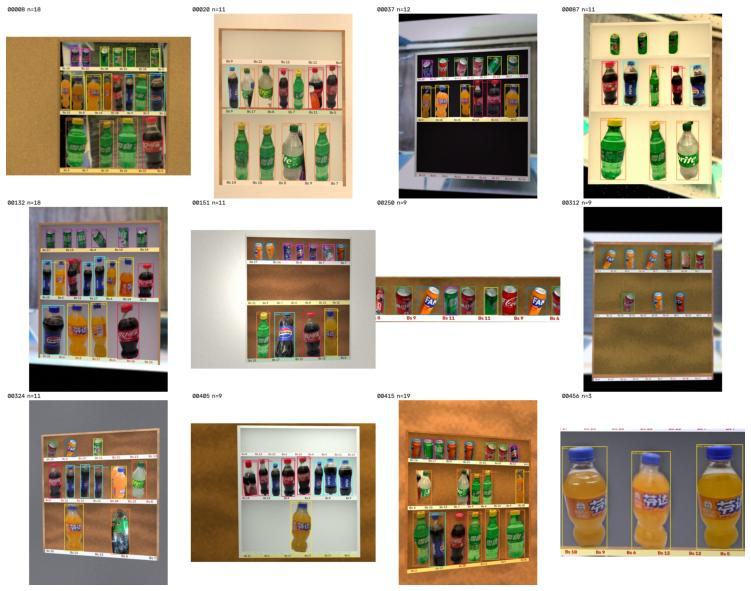

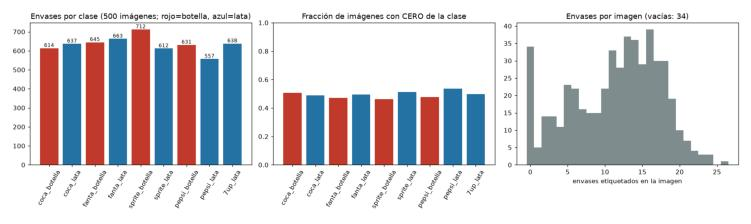

In [7]:
for nombre in ("muestras.png", "distribucion.png"):
    im = Image.open(RAIZ / "docs" / "sinteticos" / nombre)
    plt.figure(figsize=(16, 16 * im.height / im.width)); plt.imshow(im); plt.axis("off")

## Conclusiones

* Generamos ~12 imágenes/segundo con 4 procesos: 3000 estantes en ~4 minutos, balanceados (±4 % por clase),
  con ~6 % de imágenes vacías y la mitad de las imágenes con cero de cada clase.
* El cuello de botella es la biblioteca de objetos: **Fanta lata tiene solo 8 envases** distintos.
* Siguiente paso: entrenar con y sin sintéticos y comparar **en fotos reales** (val/test de la fusión y la
  maqueta). Si los sintéticos no ayudan o empeoran, es la brecha de dominio: bajar su proporción o usarlos
  solo para preentrenar.
